In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
from possessions import zone, NX, NY
from markov import N, BUT
from epoques import SAISONS
from mdp import (ACTIONS, actions_avec_type, comptages, modele, valeur_politique,
                 iteration_valeur, taux_but, politique_modifiee)

Cs = {sid: comptages(actions_avec_type(sid, dossier="../data")) for sid in SAISONS}
C_prior = sum(Cs.values())          # le Barça sur 17 saisons = a priori

In [2]:
def analyser(sid):
    a = actions_avec_type(sid, dossier="../data")
    P, pi, dispo = modele(Cs[sid], C_prior)
    V_pi = valeur_politique(P, pi)
    V_s, best, Qsa, k = iteration_valeur(P, dispo)
    return a, P, pi, dispo, V_pi, V_s, best, Qsa, k

resultats = {}
for sid in [41, 27, 90]:
    a, P, pi, dispo, V_pi, V_s, best, Qsa, k = analyser(sid)
    resultats[sid] = (a, P, pi, dispo, V_pi, V_s, best, Qsa)
    reel = (a.suivant == BUT).sum() / a.groupby([a.match_id, a.possession]).ngroups
    print(f"{SAISONS[sid][0]} : réel {reel:.2%} | modèle V_pi {taux_but(V_pi, a):.2%} | "
          f"optimal V* {taux_but(V_s, a):.2%} | itérations {k}")

2008/09 : réel 2.73% | modèle V_pi 2.66% | optimal V* 5.77% | itérations 180
2015/16 : réel 2.80% | modèle V_pi 2.74% | optimal V* 6.31% | itérations 222
2020/21 : réel 2.24% | modèle V_pi 2.31% | optimal V* 5.90% | itérations 209


In [3]:
_, P, pi, dispo, V_pi, *_ = resultats[27]
Q = P @ np.append(V_pi, [1.0, 0.0])                   # Q(s, a) sous la politique observée
Qd = np.where(dispo, Q, np.nan)
ecart = np.nanmax(Qd, axis=1) - np.nanmin(Qd, axis=1)  # meilleure − pire action, par zone
colonne = np.arange(N) // NY
for nom, c1, c2 in [("Tiers défensif", 0, 6), ("Milieu", 6, 11), ("Tiers offensif", 11, 16)]:
    print(f"{nom:15s} écart moyen entre actions : {np.nanmean(ecart[(colonne >= c1) & (colonne < c2)]):.2%}")

Tiers défensif  écart moyen entre actions : 0.11%
Milieu          écart moyen entre actions : 0.21%
Tiers offensif  écart moyen entre actions : 2.35%


In [4]:
for sid in [27, 90]:
    a, P, pi, dispo, V_pi, V_s, best, Qsa = resultats[sid]
    print(SAISONS[sid])
    for nom, x, y in [("Rond central", 60, 40), ("Entrée de surface", 100, 40),
                      ("Point de penalty", 108, 40), ("Devant le but", 116, 40)]:
        z = zone(x, y)
        q = {ACTIONS[i]: f"{Qsa[z, i]:.1%}" for i in range(4) if dispo[z, i]}
        print(f"  {nom:18s} V_pi {V_pi[z]:.1%} | meilleure : {ACTIONS[best[z]]:13s} | Q {q}")

('2015/16', 'Luis Enrique')
  Rond central       V_pi 2.7% | meilleure : passe_longue  | Q {'conduite': '6.2%', 'passe_courte': '6.2%', 'passe_longue': '6.3%'}
  Entrée de surface  V_pi 8.7% | meilleure : tir           | Q {'conduite': '12.6%', 'passe_courte': '9.5%', 'tir': '14.6%'}
  Point de penalty   V_pi 22.7% | meilleure : tir           | Q {'conduite': '17.2%', 'tir': '29.6%'}
  Devant le but      V_pi 47.0% | meilleure : tir           | Q {'tir': '51.9%'}
('2020/21', 'Koeman')
  Rond central       V_pi 2.5% | meilleure : passe_longue  | Q {'conduite': '6.4%', 'passe_courte': '6.3%', 'passe_longue': '6.4%'}
  Entrée de surface  V_pi 6.8% | meilleure : conduite      | Q {'conduite': '10.9%', 'passe_courte': '10.8%', 'tir': '8.9%'}
  Point de penalty   V_pi 16.8% | meilleure : tir           | Q {'conduite': '14.9%', 'passe_courte': '12.5%', 'tir': '22.3%'}
  Devant le but      V_pi 35.9% | meilleure : tir           | Q {'tir': '40.1%'}


In [5]:
surface = [z for z in range(N) if z // NY >= 14 and 3 <= z % NY <= 8]   # 12 zones de la surface

for sid in [27, 90]:
    a, P, pi, dispo, V_pi, *_ = resultats[sid]
    base = taux_but(V_pi, a)
    for f in [1.1, 1.25]:
        nouveau = taux_but(valeur_politique(P, politique_modifiee(pi, dispo, surface, 3, f)), a)
        print(f"{SAISONS[sid][0]} tir ×{f} dans la surface : {100 * (nouveau / base - 1):+.1f} % de buts")

2015/16 tir ×1.1 dans la surface : +4.5 % de buts
2015/16 tir ×1.25 dans la surface : +9.9 % de buts
2020/21 tir ×1.1 dans la surface : +4.3 % de buts
2020/21 tir ×1.25 dans la surface : +8.4 % de buts


In [6]:
def bootstrap_contrefactuel(sid, n=200):
    a = actions_avec_type(sid, dossier="../data")
    matchs = a.match_id.unique()
    rng = np.random.default_rng(0)
    gains = []
    for _ in range(n):
        tirage = rng.choice(matchs, len(matchs))                       # matchs tirés avec remise
        ab = pd.concat([a[a.match_id == m].assign(match_id=i) for i, m in enumerate(tirage)])
        Pb, pib, db = modele(comptages(ab), C_prior)
        b0 = taux_but(valeur_politique(Pb, pib), ab)
        b1 = taux_but(valeur_politique(Pb, politique_modifiee(pib, db, surface, 3, 1.1)), ab)
        gains.append(100 * (b1 / b0 - 1))
    return np.quantile(gains, [0.025, 0.975])

for sid in [27, 90]:
    print(SAISONS[sid][0], "IC 95 % du gain :", bootstrap_contrefactuel(sid).round(1))

2015/16 IC 95 % du gain : [3.7 4.9]
2020/21 IC 95 % du gain : [2.7 4.9]


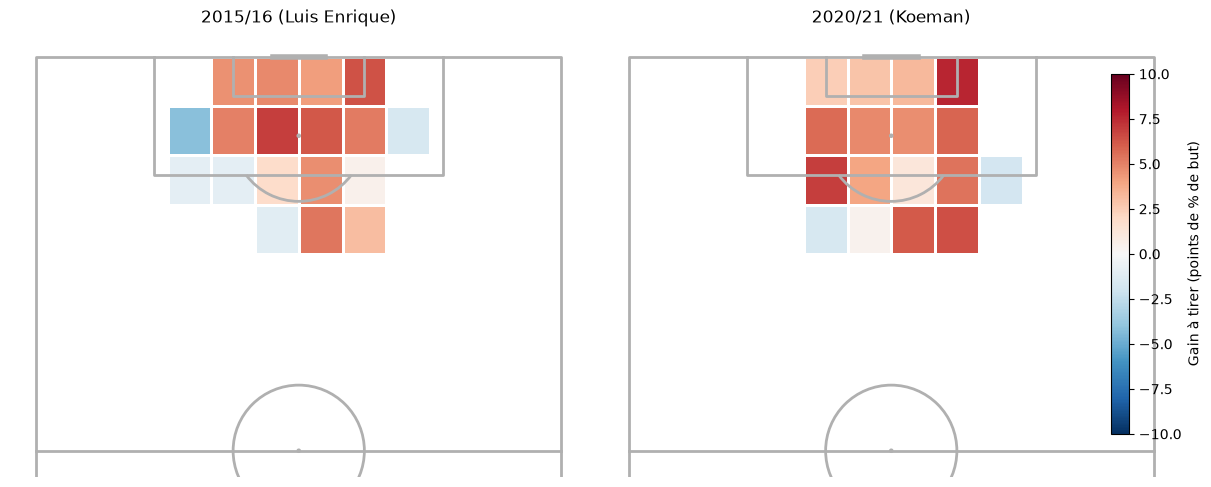

In [7]:
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from mplsoccer import VerticalPitch

pitch = VerticalPitch(pitch_type="statsbomb", half=True, line_zorder=2)
fig, axs = pitch.draw(nrows=1, ncols=2, figsize=(12, 6))
for ax, sid in zip(axs, [27, 90]):
    a, P, pi, dispo, V_pi, *_ = resultats[sid]
    Q = P @ np.append(V_pi, [1.0, 0.0])
    gain = np.where(dispo[:, 3], Q[:, 3] - V_pi, np.nan)        # tirer plutôt que continuer
    stats = pitch.bin_statistic([], [], bins=(NX, NY))
    stats["statistic"] = gain.reshape(NX, NY).T * 100
    pcm = pitch.heatmap(stats, ax=ax, cmap="RdBu_r", norm=TwoSlopeNorm(0, -10, 10), edgecolors="white")
    ax.set_title(f"{SAISONS[sid][0]} ({SAISONS[sid][1]})")
cax = fig.add_axes([0.93, 0.2, 0.015, 0.6])
fig.colorbar(pcm, cax=cax, label="Gain à tirer (points de % de but)")
fig.savefig("../figures/gain_tir.png", dpi=150, bbox_inches="tight")